# EDA Dataset Terpadu Karhutla dan Variabel Iklim (APIKAH) — Versi 2

Notebook ini **terpisah** dari `eda_apikah_new.ipynb`. Kode lama tidak ditimpa.

Sumber data:
- `dataset_apikah/variabel_iklim/*.parquet`: panel grid 0,25° berisi cuaca, indeks kekeringan, dan label hotspot (`ada_api`, `n_hotspot`, `n_hotspot_high`, `max_frp`).
- `dataset_apikah/data hotspot_indonesia/*.parquet`: deteksi hotspot VIIRS tingkat titik.

Perbedaan utama dari EDA lama:
- EDA lama membaca 500.000 baris pertama `dataset_utama_apikah.csv` (Januari–Mei 2012).
- Notebook ini membaca **seluruh periode** 1 Januari 2012 – 30 September 2026.
- Agregasi berat memakai DuckDB langsung ke Parquet, jadi 19,3 juta baris tidak perlu dimuat ke RAM.

Istilah: `ada_api = 1` berarti ada minimal satu deteksi hotspot di sel grid pada hari itu. `n_hotspot` adalah jumlah deteksi pada sel-hari tersebut.

Prasyarat: `pandas`, `pyarrow`, `duckdb`, `matplotlib`, `seaborn`, `scipy`.

## Step 0: Setup, path, dan koneksi DuckDB

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "dataset_apikah").exists() and (p / "eda_apikah").exists():
            return p
    raise FileNotFoundError("Root repo APIKAH tidak ditemukan.")

ROOT = find_root()

IKLIM_DIR = ROOT / "dataset_apikah" / "variabel_iklim"
if not IKLIM_DIR.exists():
    IKLIM_DIR = ROOT / "dataset_apikah" / "training_iklim" / "variabel_iklim"

HOTSPOT_DIR = ROOT / "dataset_apikah" / "data hotspot_indonesia"
PLOT_DIR = ROOT / "eda_apikah" / "plots_v2"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
con.execute("SET threads TO 4")

V = f"read_parquet('{IKLIM_DIR / '*.parquet'}')"
H = f"read_parquet('{HOTSPOT_DIR / '*.parquet'}')"

def q(sql):
    return con.execute(sql).fetchdf()

print("Root repo   :", ROOT)
print("Variabel iklim:", IKLIM_DIR)
print("Hotspot      :", HOTSPOT_DIR)
print("Plot         :", PLOT_DIR)

Root repo   : /home/blitzprinz/Documents/Semester 5/APIKAH
Variabel iklim: /home/blitzprinz/Documents/Semester 5/APIKAH/dataset_apikah/variabel_iklim
Hotspot      : /home/blitzprinz/Documents/Semester 5/APIKAH/dataset_apikah/data hotspot_indonesia
Plot         : /home/blitzprinz/Documents/Semester 5/APIKAH/eda_apikah/plots_v2


## Step 1: Inspeksi struktur dan cakupan data

In [2]:
display(q(f"DESCRIBE SELECT * FROM {V}"))

panel_stats = q(f"""
    SELECT count(*) AS baris,
           min(date) AS awal,
           max(date) AS akhir,
           count(DISTINCT lat_c || ',' || lon_c) AS sel,
           count(DISTINCT date) AS hari
    FROM {V}
""")
display(panel_stats)

hotspot_stats = q(f"""
    SELECT count(*) AS baris,
           min(acq_date) AS awal,
           max(acq_date) AS akhir,
           count(DISTINCT latitude || ',' || longitude) AS titik
    FROM {H}
""")
display(hotspot_stats)

,column_name,column_type,null,key,default,extra
0,date,TIMESTAMP_NS,YES,None,None,None
1,lat_c,DOUBLE,YES,None,None,None
2,lon_c,DOUBLE,YES,None,None,None
3,t2m_mean,FLOAT,YES,None,None,None
4,t2m_max,FLOAT,YES,None,None,None
5,t2m_min,FLOAT,YES,None,None,None
6,rh_mean,FLOAT,YES,None,None,None
7,rh_min,FLOAT,YES,None,None,None
8,vpd_max,FLOAT,YES,None,None,None
9,wind_max,FLOAT,YES,None,None,None


,baris,awal,akhir,sel,hari
0,19301621,2012-01-01,2026-09-30,3583,5387


,baris,awal,akhir,titik
0,3941039,2012-01-20,2026-09-30,3940287


## Step 2: Profil missing value

In [3]:
cols = q(f"DESCRIBE SELECT * FROM {V}")["column_name"].tolist()
expr = ", ".join([
    f'round(100.0 * (count(*) - count("{c}")) / count(*), 2) AS "{c}"'
    for c in cols
])
miss = q(f"SELECT count(*) AS total, {expr} FROM {V}").T.reset_index()
miss.columns = ["kolom", "persen_null"]
miss = miss[miss["kolom"] != "total"].sort_values("persen_null", ascending=False)
display(miss.head(15))

hcols = q(f"DESCRIBE SELECT * FROM {H}")["column_name"].tolist()
hexpr = ", ".join([
    f'round(100.0 * (count(*) - count("{c}")) / count(*), 2) AS "{c}"'
    for c in hcols
])
hmiss = q(f"SELECT count(*) AS total, {hexpr} FROM {H}").T.reset_index()
hmiss.columns = ["kolom", "persen_null"]
hmiss = hmiss[hmiss["kolom"] != "total"].sort_values("persen_null", ascending=False)
display(hmiss.head(10))

,kolom,persen_null
31,max_frp,95.69
27,dmi_lag1,2.28
13,fwi,1.44
15,dmc,1.44
16,kbdi,1.44
14,dc,1.44
22,hujan_30h,1.11
26,nino34_lag1,0.58
21,hujan_14h,0.52
20,hujan_7h,0.26


,kolom,persen_null
1,latitude,0.0
2,longitude,0.0
3,acq_date,0.0
4,acq_time,0.0
5,confidence,0.0
6,frp,0.0
7,bright_ti4,0.0
8,daynight,0.0
9,satellite,0.0
10,provinsi,0.0


## Step 3: Karakteristik sensor satelit (deteksi titik)

,daynight,n,pct
0,D,2601457,66.01
1,N,1339582,33.99


,confidence,n,pct
0,h,124440,3.16
1,l,238357,6.05
2,n,3578242,90.79


,produk,n,pct
0,VIIRS_SNPP_SP,2219766,56.32
1,VIIRS_NOAA20_SP,1337955,33.95
2,VIIRS_NOAA20_NRT,383318,9.73


,min,p25,median,p75,p95,p99,max,mean
0,0.0,2.32,4.57,8.45,25.95,64.95,1951.3,8.159423


,min,median,p99,max
0,207.93,333.89,367.0,367.0


,confidence,median_frp,n
0,h,14.67,124440
1,l,5.48,238357
2,n,4.33,3578242


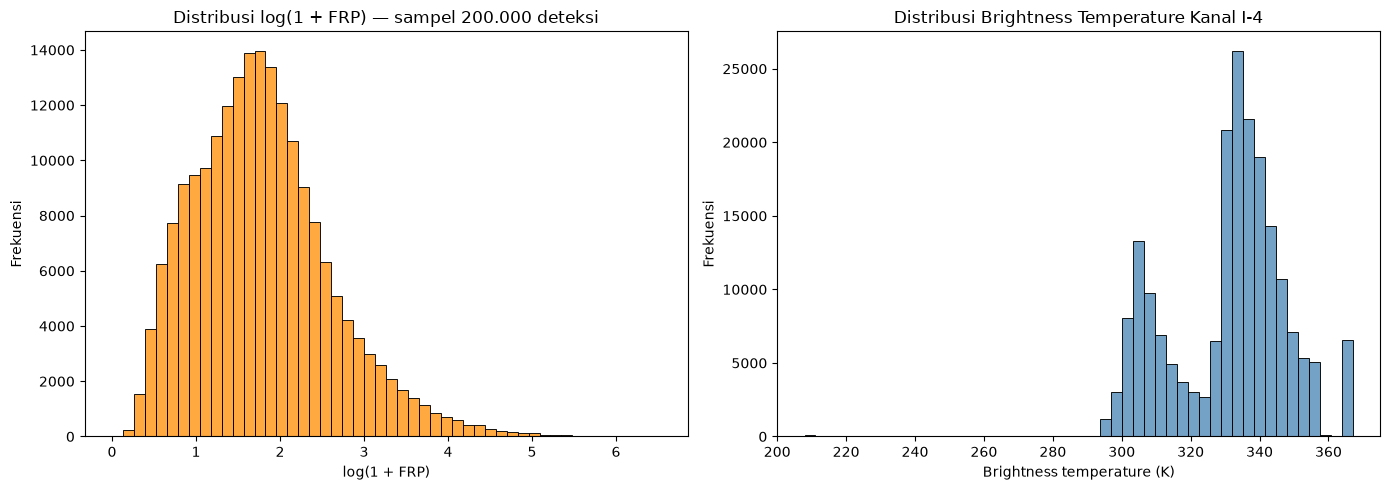

In [4]:
display(q(f"""
    SELECT daynight, count(*) AS n,
           round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
    FROM {H} GROUP BY 1 ORDER BY 1
"""))

display(q(f"""
    SELECT confidence, count(*) AS n,
           round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
    FROM {H} GROUP BY 1 ORDER BY 1
"""))

display(q(f"""
    SELECT produk, count(*) AS n,
           round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
    FROM {H} GROUP BY 1 ORDER BY 2 DESC
"""))

display(q(f"""
    SELECT min(frp) AS min, quantile_cont(frp, 0.25) AS p25,
           quantile_cont(frp, 0.50) AS median, quantile_cont(frp, 0.75) AS p75,
           quantile_cont(frp, 0.95) AS p95, quantile_cont(frp, 0.99) AS p99,
           max(frp) AS max, avg(frp) AS mean
    FROM {H}
"""))

display(q(f"""
    SELECT min(bright_ti4) AS min, quantile_cont(bright_ti4, 0.50) AS median,
           quantile_cont(bright_ti4, 0.99) AS p99, max(bright_ti4) AS max
    FROM {H}
"""))

display(q(f"""
    SELECT confidence, quantile_cont(frp, 0.50) AS median_frp, count(*) AS n
    FROM {H} GROUP BY 1 ORDER BY 1
"""))

sensor_sample = q(f"SELECT frp, bright_ti4, confidence FROM {H} USING SAMPLE 200000 ROWS")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(np.log1p(sensor_sample["frp"]), bins=50, ax=axes[0], color="darkorange")
axes[0].set_title("Distribusi log(1 + FRP) — sampel 200.000 deteksi")
axes[0].set_xlabel("log(1 + FRP)")
axes[0].set_ylabel("Frekuensi")

sns.histplot(sensor_sample["bright_ti4"], bins=50, ax=axes[1], color="steelblue")
axes[1].set_title("Distribusi Brightness Temperature Kanal I-4")
axes[1].set_xlabel("Brightness temperature (K)")
axes[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.savefig(PLOT_DIR / "karakteristik_sensor.png", dpi=150)
plt.show()

## Step 4: Distribusi target biner, hitungan hotspot, dan kelas risiko

,ada_api,n,pct
0,0,18470023,95.69
1,1,831598,4.31


,risk_class,n,pct
0,Low,18470023,95.69
1,Moderate,531563,2.75
2,High,225108,1.17
3,Extreme,74927,0.39


,min,median,p99,max,mean
0,0,0.0,4.0,1504,0.200523


,date,lat_c,lon_c,n_hotspot,n_hotspot_high,max_frp
0,2015-10-03,-2.625,105.375,1504,111,579.62
1,2015-10-06,-2.875,105.625,1129,163,329.20
2,2015-10-10,-2.875,105.625,1012,260,581.21
3,2015-10-24,-2.875,105.625,1009,140,637.93
4,2013-06-18,1.625,101.125,974,17,331.71
5,2015-10-22,-2.875,105.625,930,125,1152.73
6,2013-06-20,1.875,100.875,868,76,468.61
7,2015-10-14,-2.375,114.625,855,57,72.33
8,2013-06-19,1.625,101.125,848,55,58.22
9,2015-09-30,-2.625,105.375,843,138,106.63


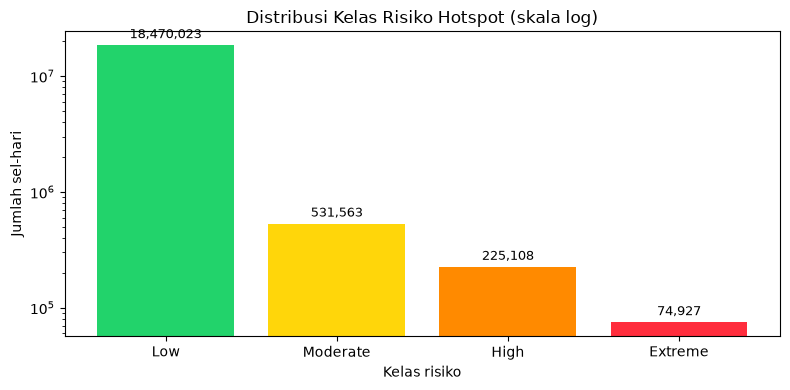

In [5]:
display(q(f"""
    SELECT ada_api, count(*) AS n,
           round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
    FROM {V} GROUP BY 1 ORDER BY 1
"""))

display(q(f"""
    SELECT CASE
             WHEN n_hotspot = 0 THEN 'Low'
             WHEN n_hotspot <= 2 THEN 'Moderate'
             WHEN n_hotspot <= 9 THEN 'High'
             ELSE 'Extreme'
           END AS risk_class,
           count(*) AS n,
           round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
    FROM {V}
    GROUP BY 1
    ORDER BY CASE risk_class
               WHEN 'Low' THEN 0 WHEN 'Moderate' THEN 1
               WHEN 'High' THEN 2 ELSE 3 END
"""))

display(q(f"""
    SELECT min(n_hotspot) AS min, quantile_cont(n_hotspot, 0.50) AS median,
           quantile_cont(n_hotspot, 0.99) AS p99, max(n_hotspot) AS max,
           avg(n_hotspot) AS mean
    FROM {V}
"""))

display(q(f"""
    SELECT date, lat_c, lon_c, n_hotspot, n_hotspot_high, max_frp
    FROM {V}
    ORDER BY n_hotspot DESC
    LIMIT 10
"""))

risk = q(f"""
    SELECT CASE
             WHEN n_hotspot = 0 THEN 'Low'
             WHEN n_hotspot <= 2 THEN 'Moderate'
             WHEN n_hotspot <= 9 THEN 'High'
             ELSE 'Extreme'
           END AS risk_class,
           count(*) AS n
    FROM {V} GROUP BY 1
""").set_index("risk_class").reindex(["Low", "Moderate", "High", "Extreme"]).reset_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(risk["risk_class"], risk["n"], color=["#22D36B", "#FFD60A", "#FF8A00", "#FF2D3D"])
ax.set_yscale("log")
ax.set_title("Distribusi Kelas Risiko Hotspot (skala log)")
ax.set_ylabel("Jumlah sel-hari")
ax.set_xlabel("Kelas risiko")
for i, v in enumerate(risk["n"]):
    ax.text(i, v * 1.15, f"{v:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(PLOT_DIR / "distribusi_kelas_risiko.png", dpi=150)
plt.show()

## Step 5: Statistik dan distribusi fitur kunci

,fitur,mean,std,min,median,p99,max,skewness
0,vpd_max,1.009,0.541,0.000,0.932,2.786,5.698,1.163
1,rh_min,74.164,11.014,11.783,75.205,95.344,100.000,-0.643
2,t2m_max,27.712,2.730,8.432,27.983,32.945,42.599,-1.268
3,fwi,2.262,5.719,0.000,0.212,30.167,83.215,3.980
4,kbdi,10.263,19.772,0.226,2.597,103.252,164.914,3.418
5,dc,80.918,150.508,3.043,22.576,784.501,1513.069,3.507
6,dmc,9.164,24.286,0.000,2.348,132.096,485.704,6.169
7,precip_mm,8.744,11.290,0.000,5.679,51.327,527.434,4.880
8,swvl1_mean,0.391,0.080,0.026,0.411,0.539,0.609,-1.373
9,wind_max,2.155,1.437,0.180,1.694,7.416,23.244,1.930


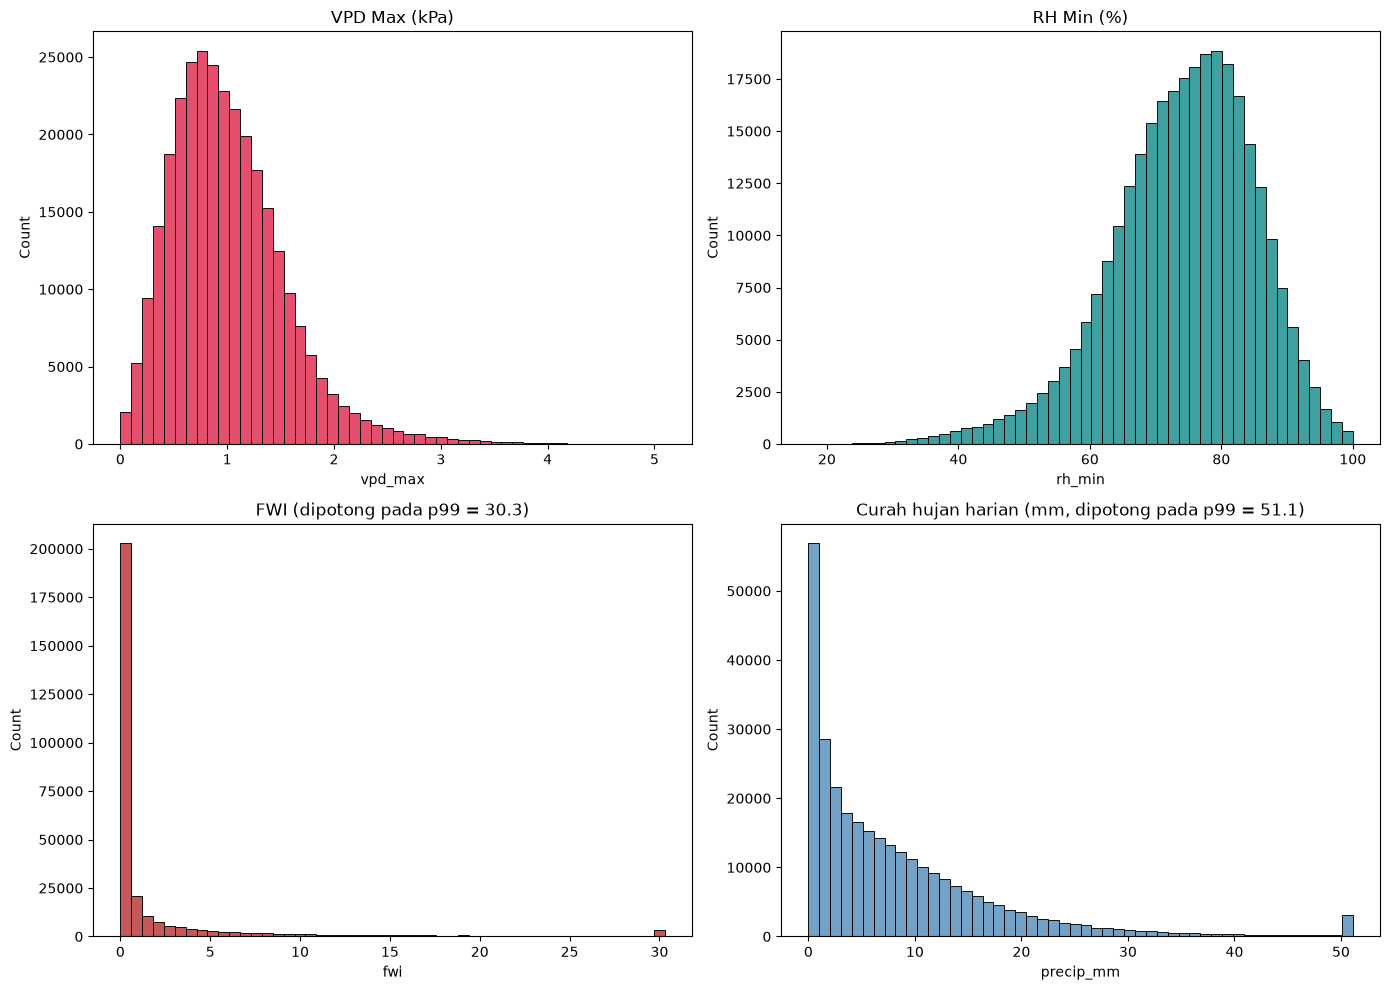

In [6]:
feats = [
    "vpd_max", "rh_min", "t2m_max", "fwi", "kbdi",
    "dc", "dmc", "precip_mm", "swvl1_mean", "wind_max",
]

sel = ", ".join([
    f"avg({f}) AS {f}_mean, stddev_samp({f}) AS {f}_std, min({f}) AS {f}_min, "
    f"quantile_cont({f}, 0.50) AS {f}_median, quantile_cont({f}, 0.99) AS {f}_p99, "
    f"max({f}) AS {f}_max, skewness({f}) AS {f}_skew"
    for f in feats
])
row = q(f"SELECT {sel} FROM {V}").iloc[0]
stats_df = pd.DataFrame({
    "fitur": feats,
    "mean": [row[f"{f}_mean"] for f in feats],
    "std": [row[f"{f}_std"] for f in feats],
    "min": [row[f"{f}_min"] for f in feats],
    "median": [row[f"{f}_median"] for f in feats],
    "p99": [row[f"{f}_p99"] for f in feats],
    "max": [row[f"{f}_max"] for f in feats],
    "skewness": [row[f"{f}_skew"] for f in feats],
})
display(stats_df.round(3))

feature_sample = q(f"SELECT vpd_max, rh_min, fwi, precip_mm FROM {V} USING SAMPLE 300000 ROWS")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(feature_sample["vpd_max"].dropna(), bins=50, ax=axes[0, 0], color="crimson")
axes[0, 0].set_title("VPD Max (kPa)")

sns.histplot(feature_sample["rh_min"].dropna(), bins=50, ax=axes[0, 1], color="teal")
axes[0, 1].set_title("RH Min (%)")

fwi_cap = feature_sample["fwi"].quantile(0.99)
sns.histplot(feature_sample["fwi"].clip(upper=fwi_cap).dropna(), bins=50, ax=axes[1, 0], color="firebrick")
axes[1, 0].set_title(f"FWI (dipotong pada p99 = {fwi_cap:.1f})")

precip_cap = feature_sample["precip_mm"].quantile(0.99)
sns.histplot(feature_sample["precip_mm"].clip(upper=precip_cap).dropna(), bins=50, ax=axes[1, 1], color="steelblue")
axes[1, 1].set_title(f"Curah hujan harian (mm, dipotong pada p99 = {precip_cap:.1f})")

plt.tight_layout()
plt.savefig(PLOT_DIR / "distribusi_fitur_kunci.png", dpi=150)
plt.show()

## Step 6: Korelasi fitur dengan target dan heatmap fitur utama

,fitur,korelasi
0,fwi,0.3171
1,kbdi,0.2911
2,dmc,0.2848
3,dc,0.2722
4,vpd_max,0.2660
8,t2m_max,0.1486
12,t2m_mean,0.0897
13,wind_max,0.0736
14,t2m_mean_anom,0.0559
16,precip_mm_anom,-0.0400


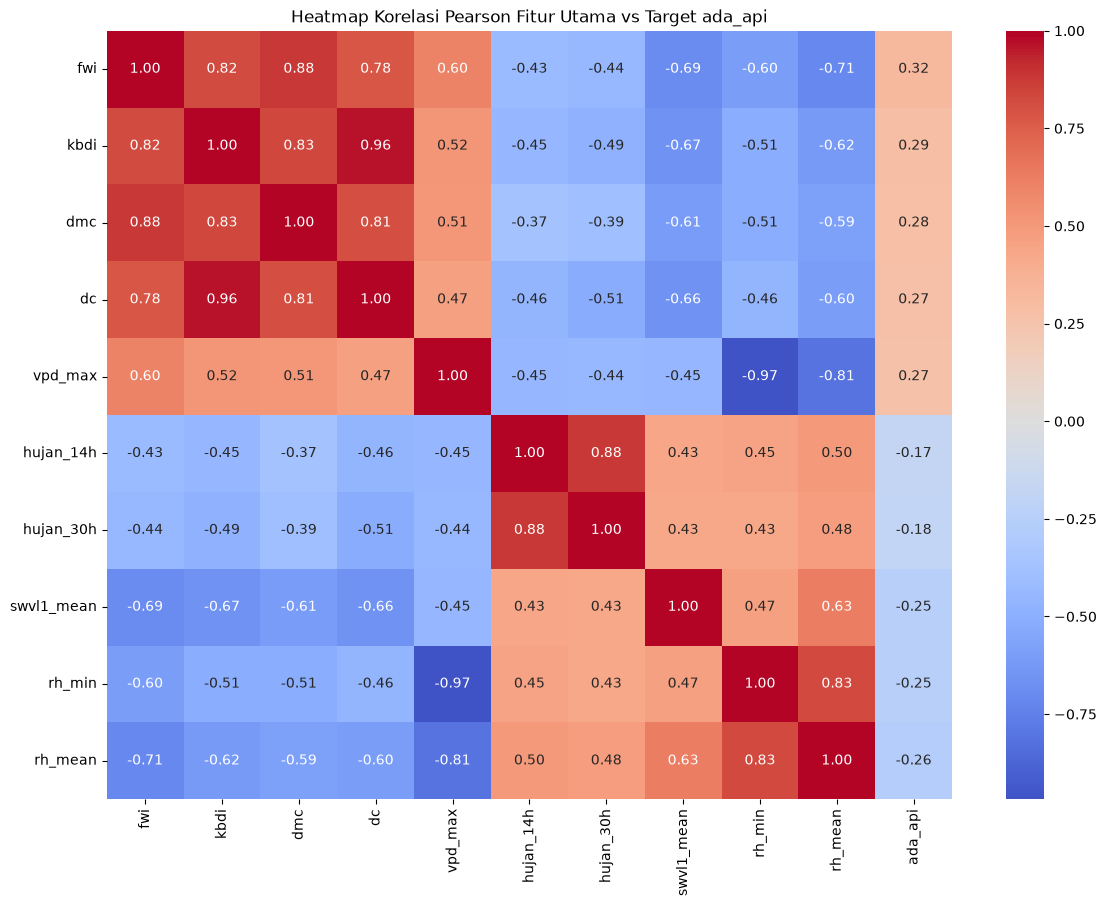

In [7]:
corr_feats = [
    "fwi", "kbdi", "dmc", "dc", "vpd_max", "rh_min", "rh_mean",
    "swvl1_mean", "t2m_max", "precip_mm", "hujan_7h", "hujan_30h",
    "t2m_mean", "wind_max", "t2m_mean_anom", "rh_mean_anom",
    "precip_mm_anom", "hujan_3h", "hujan_14h",
]
sel = ", ".join([f'corr({f}, ada_api) AS "{f}"' for f in corr_feats])
row = q(f"SELECT {sel} FROM {V}").iloc[0]
corr = pd.DataFrame({
    "fitur": corr_feats,
    "korelasi": [row[f] for f in corr_feats],
}).sort_values("korelasi", ascending=False)
display(corr.round(4))

top = corr.head(5)["fitur"].tolist() + corr.tail(5)["fitur"].tolist()
pairs = [(a, b) for i, a in enumerate(top) for b in top[i + 1:]]
sel = ", ".join([f"corr({a}, {b}) AS c{i}" for i, (a, b) in enumerate(pairs)])
vals = q(f"SELECT {sel} FROM {V}").iloc[0].tolist()

mat = pd.DataFrame(np.eye(len(top)), index=top, columns=top)
for (a, b), v in zip(pairs, vals):
    mat.loc[a, b] = v
    mat.loc[b, a] = v

mat["ada_api"] = [corr.set_index("fitur").loc[f, "korelasi"] for f in top]

plt.figure(figsize=(12, 9))
sns.heatmap(mat, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Heatmap Korelasi Pearson Fitur Utama vs Target ada_api")
plt.tight_layout()
plt.savefig(PLOT_DIR / "heatmap_korelasi.png", dpi=150)
plt.show()

## Step 7: Sebaran spasial dan konsentrasi hotspot per sel grid

,lat_c,lon_c,fires,obs,rate
964,-8.125,112.875,3526.0,5387,65.45
1253,-2.625,121.375,3277.0,5387,60.83
3376,1.375,127.625,2864.0,5387,53.17
2832,-6.125,105.875,2360.0,5387,43.81
1673,2.875,125.375,2311.0,5387,42.90
2303,-1.125,103.375,2209.0,5387,41.01
1840,-8.375,123.625,2129.0,5387,39.52
252,-3.875,122.375,2091.0,5387,38.82
2228,-2.125,115.625,2079.0,5387,38.59
448,-1.875,115.875,2057.0,5387,38.18


,sel_aktif,total_fires,sel_50,sel_80,sel_95,ncell
0,3583,831598.0,527,1173,1799,3583


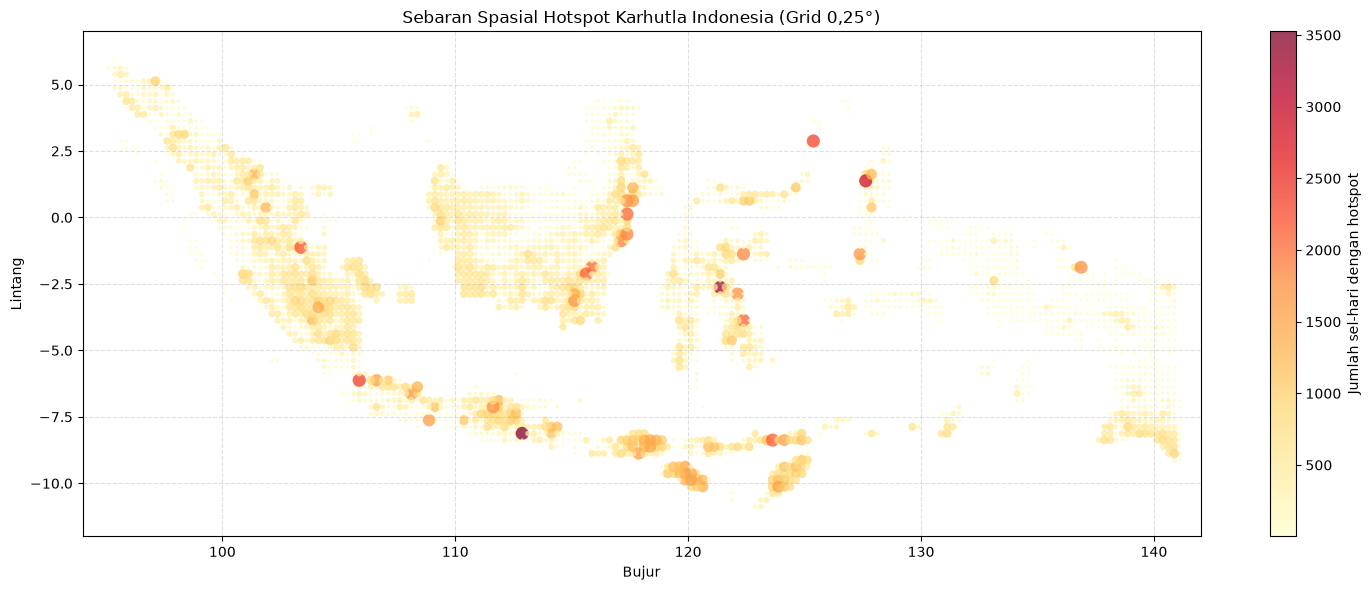

In [8]:
cell = q(f"""
    SELECT lat_c, lon_c,
           sum(ada_api) AS fires,
           count(*) AS obs,
           round(100.0 * avg(ada_api), 2) AS rate
    FROM {V}
    GROUP BY 1, 2
""")
display(cell.sort_values("fires", ascending=False).head(10))

conc = q(f"""
    WITH c AS (
        SELECT lat_c, lon_c, sum(ada_api) AS fires FROM {V} GROUP BY 1, 2
    ),
    r AS (
        SELECT fires,
               row_number() OVER (ORDER BY fires DESC) AS rn,
               sum(fires) OVER (ORDER BY fires DESC ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS cum,
               sum(fires) OVER () AS total,
               count(*) OVER () AS ncell
        FROM c
    )
    SELECT (SELECT count(*) FROM c) AS sel_aktif,
           (SELECT max(total) FROM r) AS total_fires,
           min(rn) FILTER (WHERE cum >= 0.50 * (SELECT max(total) FROM r)) AS sel_50,
           min(rn) FILTER (WHERE cum >= 0.80 * (SELECT max(total) FROM r)) AS sel_80,
           min(rn) FILTER (WHERE cum >= 0.95 * (SELECT max(total) FROM r)) AS sel_95,
           max(ncell) AS ncell
    FROM r
""")
display(conc)

plot_cell = cell[cell["fires"] > 0]
fig, ax = plt.subplots(figsize=(15, 6))
sc = ax.scatter(
    plot_cell["lon_c"], plot_cell["lat_c"],
    c=plot_cell["fires"], s=np.clip(plot_cell["fires"] / 20, 6, 90),
    cmap="YlOrRd", alpha=0.75, edgecolors="none",
)
fig.colorbar(sc, label="Jumlah sel-hari dengan hotspot")
ax.set_xlim(94, 142)
ax.set_ylim(-12, 7)
ax.set_title("Sebaran Spasial Hotspot Karhutla Indonesia (Grid 0,25°)")
ax.set_xlabel("Bujur")
ax.set_ylabel("Lintang")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(PLOT_DIR / "peta_spasial_hotspot.png", dpi=150)
plt.show()

## Step 8: Peringkat provinsi dan distribusi pulau

,provinsi,deteksi,pct
0,KalimantanTengah,606720,15.39
1,KalimantanBarat,454161,11.52
2,SumateraSelatan,421948,10.71
3,Riau,397563,10.09
4,Papua,282956,7.18
5,NusaTenggaraTimur,249728,6.34
6,KalimantanTimur,214716,5.45
7,KalimantanSelatan,155648,3.95
8,Jambi,135214,3.43
9,NusaTenggaraBarat,103645,2.63


,provinsi,deteksi,pct
24,SulawesiUtara,22193,0.56
25,PapuaBarat,19157,0.49
26,Bengkulu,18012,0.46
27,KepulauanRiau,17745,0.45
28,Gorontalo,17647,0.45
29,Banten,15218,0.39
30,SulawesiBarat,14728,0.37
31,Bali,2667,0.07
32,Yogyakarta,1870,0.05
33,JakartaRaya,765,0.02


,provinsi,fires,obs,rate
0,NusaTenggaraBarat,27984.0,215480.0,12.99
1,NusaTenggaraTimur,69437.0,549474.0,12.64
2,KalimantanSelatan,28694.0,285511.0,10.05
3,BangkaBelitung,17625.0,177771.0,9.91
4,SumateraSelatan,57810.0,624892.0,9.25
5,JawaTimur,38818.0,441734.0,8.79
6,Gorontalo,6795.0,91579.0,7.42
7,Jambi,26106.0,360929.0,7.23
8,KalimantanTimur,59203.0,851146.0,6.96
9,Riau,47999.0,705697.0,6.80


,pulau,n,pct
0,Kalimantan,1461092.0,37.07
1,Sumatera,1253703.0,31.81
2,Maluku & Papua,418693.0,10.62
3,Bali & Nusa Tenggara,356040.0,9.03
4,Sulawesi,270184.0,6.86
5,Jawa,181327.0,4.60


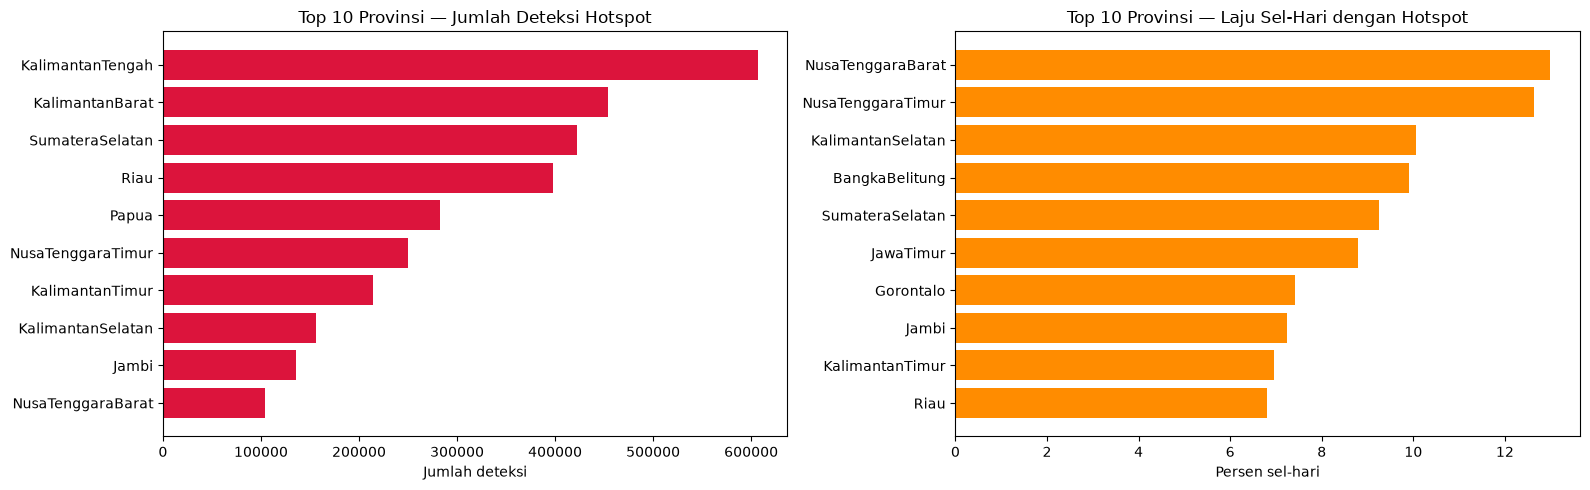

In [9]:
prov = q(f"""
    SELECT provinsi, count(*) AS deteksi,
           round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
    FROM {H} GROUP BY 1 ORDER BY 2 DESC
""")
display(prov.head(10))
display(prov.tail(10))

prov_rate = q(f"""
    WITH hp AS (
        SELECT floor(latitude / 0.25) * 0.25 + 0.125 AS lat_c,
               floor(longitude / 0.25) * 0.25 + 0.125 AS lon_c,
               provinsi, count(*) AS n
        FROM {H} GROUP BY 1, 2, 3
    ),
    cp AS (
        SELECT lat_c, lon_c, arg_max(provinsi, n) AS provinsi FROM hp GROUP BY 1, 2
    ),
    cs AS (
        SELECT lat_c, lon_c, sum(ada_api) AS fires, count(*) AS obs
        FROM {V} GROUP BY 1, 2
    )
    SELECT p.provinsi, sum(s.fires) AS fires, sum(s.obs) AS obs,
           round(100.0 * sum(s.fires) / sum(s.obs), 2) AS rate
    FROM cs s JOIN cp p USING (lat_c, lon_c)
    GROUP BY 1
    HAVING sum(s.obs) >= 10000
    ORDER BY rate DESC
""")
display(prov_rate.head(12))

island = q(f"""
    WITH hp AS (SELECT provinsi, count(*) AS n FROM {H} GROUP BY 1)
    SELECT CASE
             WHEN regexp_matches(lower(provinsi), 'aceh|sumatera|riau|jambi|bengkulu|lampung|bangka') THEN 'Sumatera'
             WHEN regexp_matches(lower(provinsi), 'jawa|banten|jakarta|yogyakarta') THEN 'Jawa'
             WHEN regexp_matches(lower(provinsi), 'kalimantan') THEN 'Kalimantan'
             WHEN regexp_matches(lower(provinsi), 'sulawesi|gorontalo') THEN 'Sulawesi'
             WHEN regexp_matches(lower(provinsi), 'bali|nusatenggara') THEN 'Bali & Nusa Tenggara'
             WHEN regexp_matches(lower(provinsi), 'maluku|papua') THEN 'Maluku & Papua'
             ELSE 'Lainnya' END AS pulau,
           sum(n) AS n,
           round(100.0 * sum(n) / sum(sum(n)) OVER (), 2) AS pct
    FROM hp GROUP BY 1 ORDER BY n DESC
""")
display(island)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
top10 = prov.head(10).sort_values("deteksi")
axes[0].barh(top10["provinsi"], top10["deteksi"], color="crimson")
axes[0].set_title("Top 10 Provinsi — Jumlah Deteksi Hotspot")
axes[0].set_xlabel("Jumlah deteksi")

top_rate = prov_rate.head(10).sort_values("rate")
axes[1].barh(top_rate["provinsi"], top_rate["rate"], color="darkorange")
axes[1].set_title("Top 10 Provinsi — Laju Sel-Hari dengan Hotspot")
axes[1].set_xlabel("Persen sel-hari")

plt.tight_layout()
plt.savefig(PLOT_DIR / "peringkat_provinsi.png", dpi=150)
plt.show()

## Step 9: Pola temporal, musiman, dan baseline persistensi

,tahun,n
0,2012,317705
1,2013,256871
2,2014,551669
3,2015,874521
4,2016,116629
5,2017,90433
6,2018,192281
7,2019,436391
8,2020,92814
9,2021,70654


,bulan,n,pct
0,1,58678,1.49
1,2,122687,3.11
2,3,150439,3.82
3,4,57836,1.47
4,5,64405,1.63
5,6,186304,4.73
6,7,270868,6.87
7,8,703923,17.86
8,9,1227473,31.15
9,10,850467,21.58


,pct_aug_oct
0,70.59


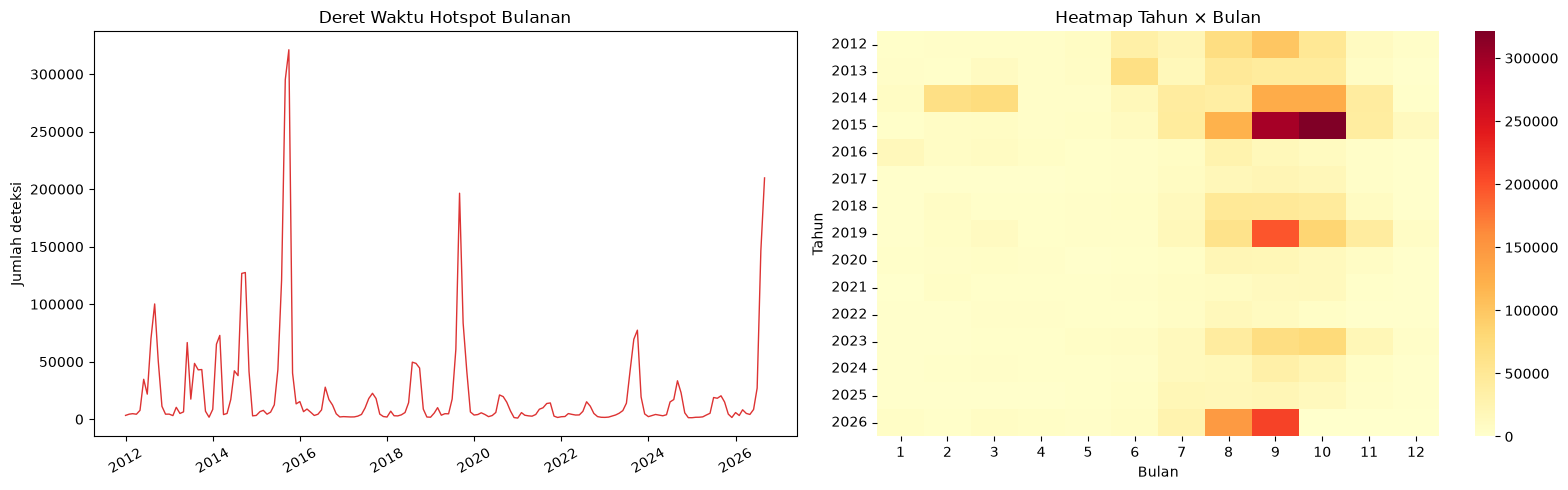

In [10]:
monthly = q(f"""
    SELECT date_trunc('month', acq_date::DATE) AS bulan, count(*) AS n
    FROM {H} GROUP BY 1 ORDER BY 1
""")
yearly = q(f"""
    SELECT year(acq_date::DATE) AS tahun, count(*) AS n
    FROM {H} GROUP BY 1 ORDER BY 1
""")
month_avg = q(f"""
    SELECT month(acq_date::DATE) AS bulan, count(*) AS n,
           round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
    FROM {H} GROUP BY 1 ORDER BY 1
""")
aug_oct = q(f"""
    SELECT round(100.0 * sum(CASE WHEN month(acq_date::DATE) BETWEEN 8 AND 10 THEN 1 ELSE 0 END) / count(*), 2) AS pct_aug_oct
    FROM {H}
""")
display(yearly)
display(month_avg)
display(aug_oct)

ym = q(f"""
    SELECT year(acq_date::DATE) AS tahun, month(acq_date::DATE) AS bulan, count(*) AS n
    FROM {H} GROUP BY 1, 2 ORDER BY 1, 2
""")
pivot = ym.pivot(index="tahun", columns="bulan", values="n").fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(monthly["bulan"], monthly["n"], color="#d33", lw=1.0)
axes[0].set_title("Deret Waktu Hotspot Bulanan")
axes[0].set_ylabel("Jumlah deteksi")
axes[0].tick_params(axis="x", rotation=30)

sns.heatmap(pivot, cmap="YlOrRd", ax=axes[1])
axes[1].set_title("Heatmap Tahun × Bulan")
axes[1].set_xlabel("Bulan")
axes[1].set_ylabel("Tahun")

plt.tight_layout()
plt.savefig(PLOT_DIR / "tren_musiman_tahunan.png", dpi=150)
plt.show()

In [11]:
julsep = q(f"""
    SELECT year(acq_date::DATE) AS tahun, count(*) AS n
    FROM {H}
    WHERE month(acq_date::DATE) BETWEEN 7 AND 9
    GROUP BY 1 ORDER BY 1
""")
tau, pval = stats.kendalltau(julsep["tahun"], julsep["n"])
slope, intercept, lo, hi = stats.theilslopes(julsep["n"], julsep["tahun"])
print("Tren Jul-Sep 2012-2026 (2012 dan 2026 parsial)")
print(f"Kendall tau = {tau:+.3f}, p = {pval:.3f}")
print(f"Theil-Sen   = {slope:+,.0f}/tahun (CI95 {lo:+,.0f} s/d {hi:+,.0f})")

grid_month = q(f"""
    SELECT month(date) AS bulan, round(100.0 * avg(ada_api), 2) AS rate,
           sum(ada_api) AS fires, count(*) AS obs
    FROM {V} GROUP BY 1 ORDER BY 1
""")
display(grid_month)

baseline = q(f"""
    WITH g AS (
        SELECT lat_c, lon_c, date, ada_api,
               lead(ada_api, 1) OVER (PARTITION BY lat_c, lon_c ORDER BY date) AS l1,
               lead(ada_api, 2) OVER (PARTITION BY lat_c, lon_c ORDER BY date) AS l2,
               lead(ada_api, 3) OVER (PARTITION BY lat_c, lon_c ORDER BY date) AS l3
        FROM {V}
    ),
    h AS (
        SELECT *, CASE WHEN l1 = 1 OR l2 = 1 OR l3 = 1 THEN 1 ELSE 0 END AS y
        FROM g WHERE l1 IS NOT NULL AND l2 IS NOT NULL AND l3 IS NOT NULL
    )
    SELECT count(*) AS n,
           round(100.0 * avg(y), 2) AS base_rate,
           round(100.0 * avg(CASE WHEN ada_api = 1 THEN y END), 2) AS p_y_given_fire,
           round(100.0 * avg(CASE WHEN ada_api = 0 THEN y END), 2) AS p_y_given_nofire,
           round(100.0 * sum(CASE WHEN ada_api = 1 AND y = 1 THEN 1 ELSE 0 END) / sum(y), 2) AS recall_persistence,
           round(100.0 * sum(CASE WHEN ada_api = 1 AND y = 1 THEN 1 ELSE 0 END) / sum(ada_api), 2) AS precision_persistence
    FROM h
""")
display(baseline)

Tren Jul-Sep 2012-2026 (2012 dan 2026 parsial)
Kendall tau = -0.143, p = 0.495
Theil-Sen   = -4,292/tahun (CI95 -17,754 s/d +8,042)


,bulan,rate,fires,obs
0,1,1.31,21825.0,1666095
1,2,1.85,28128.0,1519192
2,3,2.07,34422.0,1666095
3,4,1.64,26419.0,1612350
4,5,1.95,32554.0,1666095
5,6,3.11,50104.0,1612350
6,7,5.14,85674.0,1666095
7,8,8.98,149679.0,1666095
8,9,11.65,187892.0,1612350
9,10,9.06,140811.0,1555022


,n,base_rate,p_y_given_fire,p_y_given_nofire,recall_persistence,precision_persistence
0,19290872,8.64,62.77,6.21,31.23,62.77


## Step 10: Deteksi sumber panas non-kebakaran (flare industri)

Ambang: sel harus punya minimal 365 hari observasi dan laju sel-hari positif di atas 35%. Syarat minimal hari mencegah sel dengan 1–2 observasi ikut terdeteksi.

,lat_c,lon_c,fires,obs,rate,provinsi
0,-8.125,112.875,3526.0,5387,65.45,JawaTimur
1,-2.625,121.375,3277.0,5387,60.83,SulawesiSelatan
2,1.375,127.625,2864.0,5387,53.17,MalukuUtara
3,-6.125,105.875,2360.0,5387,43.81,Banten
4,2.875,125.375,2311.0,5387,42.90,SulawesiUtara
5,-1.125,103.375,2209.0,5387,41.01,Jambi
6,-8.375,123.625,2129.0,5387,39.52,NusaTenggaraTimur
7,-3.875,122.375,2091.0,5387,38.82,SulawesiTenggara
8,-2.125,115.625,2079.0,5387,38.59,KalimantanSelatan
9,-1.875,115.875,2057.0,5387,38.18,KalimantanTimur


,sel_gt20,sel_gt35,total_sel
0,71,11,3583


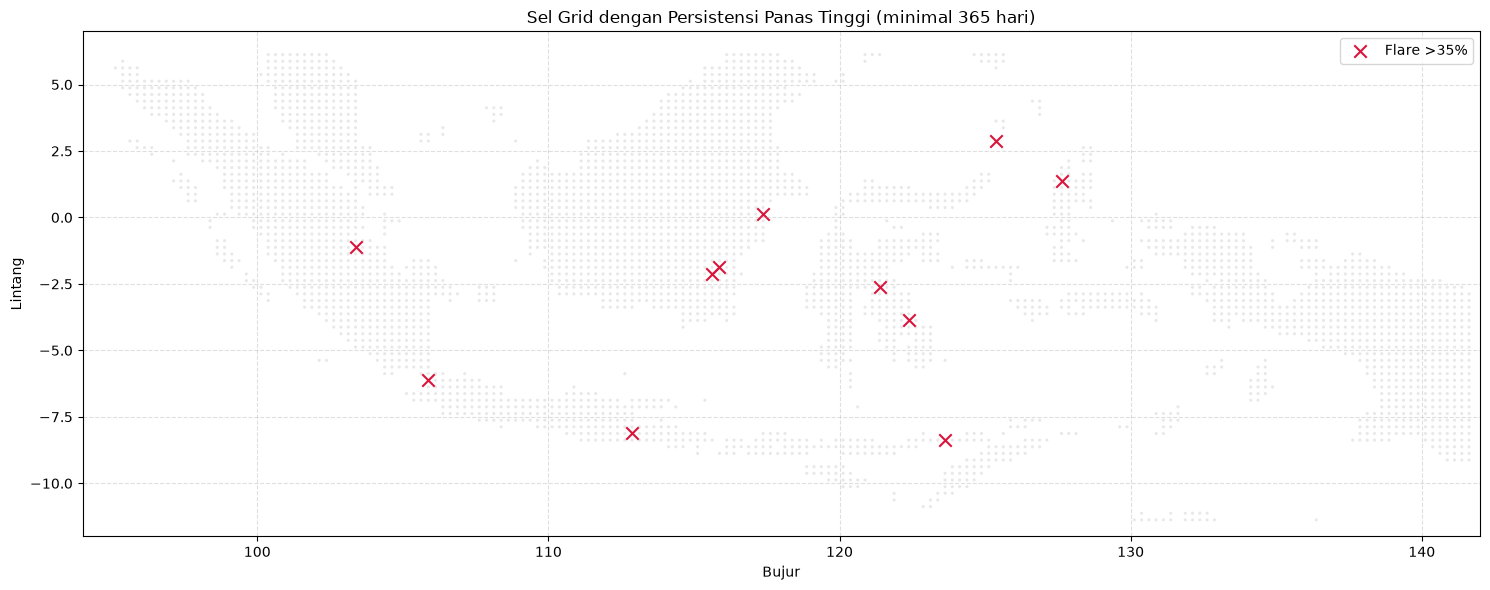

In [12]:
flare = q(f"""
    WITH hp AS (
        SELECT floor(latitude / 0.25) * 0.25 + 0.125 AS lat_c,
               floor(longitude / 0.25) * 0.25 + 0.125 AS lon_c,
               provinsi, count(*) AS n
        FROM {H} GROUP BY 1, 2, 3
    ),
    cp AS (
        SELECT lat_c, lon_c, arg_max(provinsi, n) AS provinsi FROM hp GROUP BY 1, 2
    ),
    c AS (
        SELECT lat_c, lon_c, sum(ada_api) AS fires, count(*) AS obs,
               round(100.0 * avg(ada_api), 2) AS rate
        FROM {V} GROUP BY 1, 2
    )
    SELECT c.lat_c, c.lon_c, c.fires, c.obs, c.rate, p.provinsi
    FROM c LEFT JOIN cp p USING (lat_c, lon_c)
    WHERE c.obs >= 365 AND c.rate > 35
    ORDER BY c.rate DESC
""")
display(flare)

flare_counts = q(f"""
    WITH c AS (
        SELECT lat_c, lon_c, sum(ada_api) AS fires, count(*) AS obs,
               round(100.0 * avg(ada_api), 2) AS rate
        FROM {V} GROUP BY 1, 2
    )
    SELECT count(*) FILTER (WHERE rate > 20) AS sel_gt20,
           count(*) FILTER (WHERE rate > 35) AS sel_gt35,
           count(*) AS total_sel
    FROM c WHERE obs >= 365
""")
display(flare_counts)

fig, ax = plt.subplots(figsize=(15, 6))
ax.scatter(cell["lon_c"], cell["lat_c"], c="#d9d9d9", s=5, alpha=0.6, edgecolors="none")
ax.scatter(flare["lon_c"], flare["lat_c"], c="crimson", s=80, marker="x", label="Flare >35%")
ax.set_xlim(94, 142)
ax.set_ylim(-12, 7)
ax.set_title("Sel Grid dengan Persistensi Panas Tinggi (minimal 365 hari)")
ax.set_xlabel("Bujur")
ax.set_ylabel("Lintang")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(PLOT_DIR / "flare_industri.png", dpi=150)
plt.show()

## Step 11: Keputusan fitur dan rencana modeling

Ringkasan keputusan berdasarkan hasil di atas. Daftar ini sengaja konservatif: fitur yang redundan atau berpotensi bocor dipisahkan.

In [13]:
selected_features = [
    "lat_c", "lon_c", "bulan", "hari_dalam_tahun",
    "t2m_max", "rh_min", "vpd_max", "wind_max", "swvl1_mean",
    "precip_mm", "fwi", "dc", "kbdi",
    "hujan_7h", "hujan_30h",
]

leakage_features = [
    "frp", "bright_ti4", "confidence", "daynight", "satellite",
    "produk", "acq_time", "max_frp", "n_hotspot_high",
]

redundant_features = [
    "t2m_mean", "t2m_min", "rh_mean", "dmc", "hujan_3h", "hujan_14h",
]

print("Fitur prediktor yang diusulkan:", len(selected_features))
print(selected_features)
print()
print("Fitur leakage / identitas sensor:", leakage_features)
print()
print("Fitur redundan yang dipertimbangkan untuk dibuang:", redundant_features)
print()
print("Catatan:")
print("- Semua fitur cuaca harus tersedia sampai hari t, bukan t+1.")
print("- Jika model operasional memakai prakiraan cuaca, lakukan evaluasi terpisah.")
print("- `n_hotspot`, `ada_api`, `target_lead*` adalah target, bukan fitur.")
print("- `satellite` dan `produk` mengidentifikasi era sensor, jadi tidak boleh menjadi fitur.")

Fitur prediktor yang diusulkan: 15
['lat_c', 'lon_c', 'bulan', 'hari_dalam_tahun', 't2m_max', 'rh_min', 'vpd_max', 'wind_max', 'swvl1_mean', 'precip_mm', 'fwi', 'dc', 'kbdi', 'hujan_7h', 'hujan_30h']

Fitur leakage / identitas sensor: ['frp', 'bright_ti4', 'confidence', 'daynight', 'satellite', 'produk', 'acq_time', 'max_frp', 'n_hotspot_high']

Fitur redundan yang dipertimbangkan untuk dibuang: ['t2m_mean', 't2m_min', 'rh_mean', 'dmc', 'hujan_3h', 'hujan_14h']

Catatan:
- Semua fitur cuaca harus tersedia sampai hari t, bukan t+1.
- Jika model operasional memakai prakiraan cuaca, lakukan evaluasi terpisah.
- `n_hotspot`, `ada_api`, `target_lead*` adalah target, bukan fitur.
- `satellite` dan `produk` mengidentifikasi era sensor, jadi tidak boleh menjadi fitur.


## Step 12: Ringkasan angka utama

Sel ini mencetak angka kunci dari hasil query di atas. Angka yang sama juga dilaporkan di chat.

In [14]:
summary = pd.DataFrame([
    ("Baris panel variabel iklim", f"{int(panel_stats.loc[0, 'baris']):,}"),
    ("Sel grid", f"{int(panel_stats.loc[0, 'sel']):,}"),
    ("Hari", f"{int(panel_stats.loc[0, 'hari']):,}"),
    ("Deteksi hotspot", f"{int(hotspot_stats.loc[0, 'baris']):,}"),
    ("Sel-hari positif (ada_api=1)", f"{int(cell['fires'].sum()):,}"),
    ("Laju sel-hari positif", f"{100 * cell['fires'].sum() / panel_stats.loc[0, 'baris']:.2f}%"),
    ("Puncak bulanan (deteksi)", "September"),
    ("Porsi Agustus-Oktober", f"{aug_oct.loc[0, 'pct_aug_oct']:.2f}%"),
    ("Baseline persistensi: presisi", f"{baseline.loc[0, 'precision_persistence']:.2f}%"),
    ("Baseline persistensi: recall", f"{baseline.loc[0, 'recall_persistence']:.2f}%"),
    ("Sel untuk 50% hotspot", f"{int(conc.loc[0, 'sel_50']):,}"),
    ("Sel untuk 80% hotspot", f"{int(conc.loc[0, 'sel_80']):,}"),
    ("Sel untuk 95% hotspot", f"{int(conc.loc[0, 'sel_95']):,}"),
    ("Sel flare >35% (min 365 hari)", f"{int(flare_counts.loc[0, 'sel_gt35']):,}"),
], columns=["Metrik", "Nilai"])
display(summary)

,Metrik,Nilai
0,Baris panel variabel iklim,"19,301,621"
1,Sel grid,"3,583"
2,Hari,"5,387"
3,Deteksi hotspot,"3,941,039"
4,Sel-hari positif (ada_api=1),"831,598"
5,Laju sel-hari positif,4.31%
6,Puncak bulanan (deteksi),September
7,Porsi Agustus-Oktober,70.59%
8,Baseline persistensi: presisi,62.77%
9,Baseline persistensi: recall,31.23%
